Normal Training Images: (26337, 784)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0168 - mae: 0.0956 - val_loss: 0.0108 - val_mae: 0.0741
Epoch 2/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0092 - mae: 0.0675 - val_loss: 0.0083 - val_mae: 0.0631
Epoch 3/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0078 - mae: 0.0614 - val_loss: 0.0074 - val_mae: 0.0601
Epoch 4/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0070 - mae: 0.0583 - val_loss: 0.0068 - val_mae: 0.0573
Epoch 5/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0065 - mae: 0.0563 - val_loss: 0.0063 - val_mae: 0.0551
Epoch 6/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0061 - mae: 0.0546 - val_loss: 0.0060 - val_mae: 0.0537
Epoch 7/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0058 - mae: 0.0532 - val_loss: 0.0060 - val_mae: 0.0558
Epoch 8/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0056 - mae: 0.0522 - val_loss: 0.0055 - val_mae: 0.0520
Epoch 9/10
741/741 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

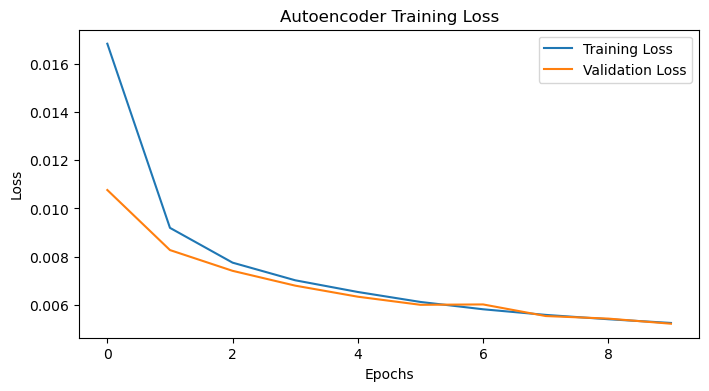

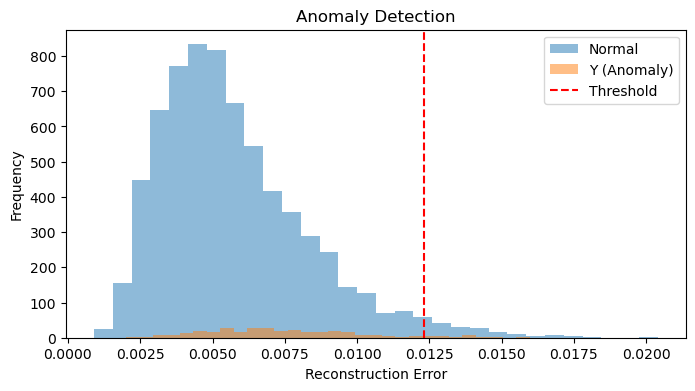

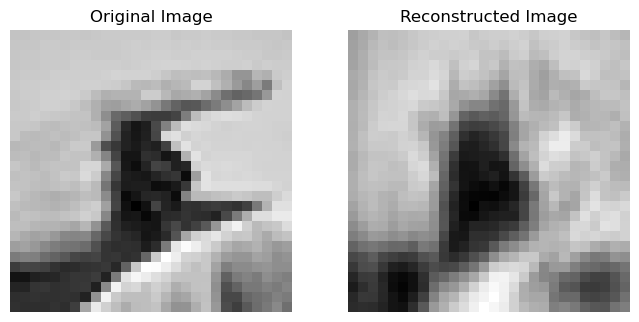

In [1]:
# Assignment 3F: Sign Language Anomaly Detection

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam


# Step 2: Load Dataset
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")


# Step 3: Separate Features and Labels
X_train = train.iloc[:, 1:].values
y_train = train.iloc[:, 0].values

X_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values


# Step 4: Normalize Pixel Values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0


# Step 5: Select Y (Label 24) as Anomaly
anomaly_label = 24

# Train only on the remaining 23 classes
X_train_normal = X_train[y_train != anomaly_label]

print("Normal Training Images:", X_train_normal.shape)


# Step 6: Create Binary Test Labels
# 0 = Normal (other 23 classes)
# 1 = Anomaly (letter Y)

y_test_binary = (y_test == anomaly_label).astype(int)


# Step 7: Build Autoencoder
model = Sequential([
    Input(shape=(784,)),

    # Encoder
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),

    # Decoder
    Dense(128, activation="relu"),
    Dense(784, activation="sigmoid")
])


# Step 8: Compile Model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


# Step 9: Train Autoencoder
history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=True
)


# Step 10: Calculate Training Reconstruction Error
train_predictions = model.predict(
    X_train_normal,
    verbose=0
)

train_error = np.mean(
    np.square(X_train_normal - train_predictions),
    axis=1
)


# Step 11: Set Threshold
threshold = np.percentile(train_error, 99)

print("Threshold:", threshold)


# Step 12: Calculate Test Reconstruction Error
test_predictions = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=1
)


# Step 13: Detect Anomalies
y_pred = (test_error > threshold).astype(int)


# Step 14: Evaluate Model
print("Accuracy:", accuracy_score(y_test_binary, y_pred))

print("Precision:", precision_score(
    y_test_binary, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_binary, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_binary, y_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_binary, y_pred))


# Step 15: Plot Training Loss
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()


# Step 16: Plot Reconstruction Errors
plt.figure(figsize=(8, 4))

plt.hist(
    test_error[y_test_binary == 0],
    bins=30,
    alpha=0.5,
    label="Normal"
)

plt.hist(
    test_error[y_test_binary == 1],
    bins=30,
    alpha=0.5,
    label="Y (Anomaly)"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.title("Anomaly Detection")
plt.legend()
plt.show()


# Step 17: Display Original and Reconstructed Image
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test[0].reshape(28, 28), cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(test_predictions[0].reshape(28, 28), cmap="gray")
plt.title("Reconstructed Image")
plt.axis("off")

plt.show()